## 02 Feature Engineering - Used Vehicle Price Prediction

**Alec Blevins**
**STA 334 - Final Project**

### Purpose
This notebook prepares the modeling subset for the pricing model. It executes the cleaning plan motivated by `01_eda.ipynb` and by diagnostic analysis of the raw data. 

### Reframed scope

Earlier drafts of this project attempted to recover missing categorical attributes (`cylinders`, `drive`, `fuel`, `transmission`) from the free-text `description` feild. Two findings from the EDA ruled this out: 
1. **The description is dominated by boilerplate.** Dealer posts on Craigslist frequently contain 1,500+ words of identical template text repeated across hundreds of listings. The vehicle-specific context is a small fraction of the field, and is often polluted by other template values, making text extraction impossible. 
2. **Where description and structured field disagree, the description is often the error.** The structured fields come from dropdowns on the listing form and are the more reliable source of truth.

A second issue is more fundamental: used-car listings include two structurally different populations mixed into one file. 
- **Normal listings** ask a price roughly consistent with age, mileage, and type. 
- **Distressed listings** - salvage, rebuilds, project cars, blown engines, "mechanic specials" - are listed at prices that have no relationship to their observable characteristics, because the price reflects what is left of a broken vehicle. 

A single model on the combined data fails, becuase the price-generating process is different in the two populations. We therefore scope the modeling sample to a defensible homogeneuous population using **structured fields only**: clean-title, plausibly-priced, modern used vehicles in reasonable condition. 

This notebook documents the diagnostic analysis that motivates each filter, executes the filtering sequence, constructs derived features and text-based feature flags, and saves the modeling subset. 

### Notebook Structure
1. Diagnostic analysis of the raw data
2. Sequential filtering
3. Text-derived feature flags
4. Derived predictors and target transformation
5. Final subset + save


### Imports & Load

In [1]:
#Library Imports
import pandas as pd
import numpy as np
import re
from pathlib import Path
import matplotlib.pyplot as plt

#Pandas Options
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

#Paths
RAW_PATH = Path("C:\\Users\\alecp\\MyPrograms\\STA 334\\used_vehicle_prediction\\vehicle_data\\raw\\vehicles.csv")
OUT_DIR = Path("C:\\Users\\alecp\\MyPrograms\\STA 334\\used_vehicle_prediction\\vehicle_data\\processed")
OUT_DIR.mkdir(parents=True, exist_ok=True)

#Grab raw
df = pd.read_csv(RAW_PATH, low_memory=False)
print(df.shape)
print(df.head())


(426880, 26)
           id                                                url                  region                         region_url  price  year manufacturer model condition cylinders fuel  odometer  \
0  7222695916  https://prescott.craigslist.org/cto/d/prescott...                prescott    https://prescott.craigslist.org   6000   NaN          NaN   NaN       NaN       NaN  NaN       NaN   
1  7218891961  https://fayar.craigslist.org/ctd/d/bentonville...            fayetteville       https://fayar.craigslist.org  11900   NaN          NaN   NaN       NaN       NaN  NaN       NaN   
2  7221797935  https://keys.craigslist.org/cto/d/summerland-k...            florida keys        https://keys.craigslist.org  21000   NaN          NaN   NaN       NaN       NaN  NaN       NaN   
3  7222270760  https://worcester.craigslist.org/cto/d/west-br...  worcester / central MA   https://worcester.craigslist.org   1500   NaN          NaN   NaN       NaN       NaN  NaN       NaN   
4  7210384030  ht

### Section 1 - Diagnostic Analysis

Before filtering, we characterize the raw data to motivate the cleaning decisions. In other words, our goal is to show *why* the modeling sample needs to be scoped, not to assume it. Each subsection examines one variable or signal and quantifies how it correlates with distress. 


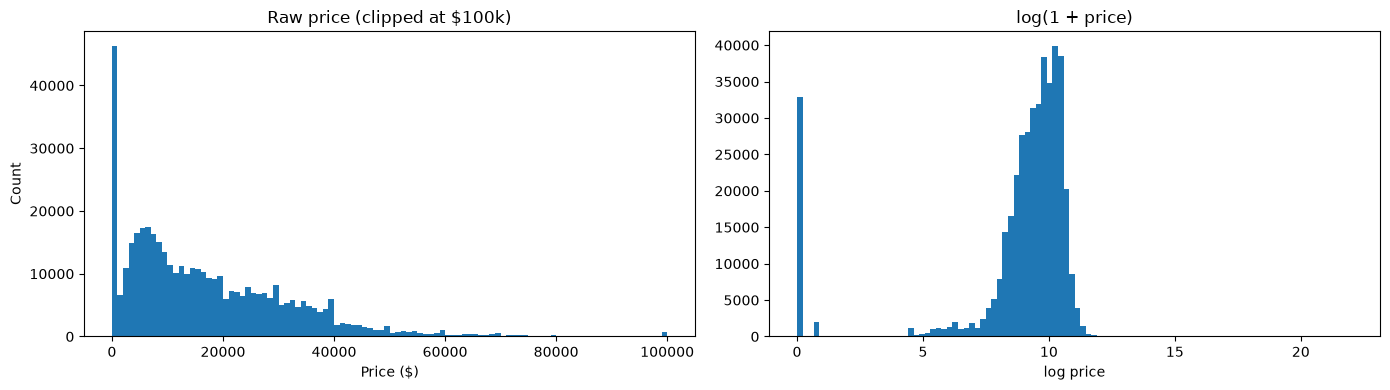

Price quantiles:
0.001         0.0
0.010         0.0
0.050         0.0
0.100       500.0
0.250      5900.0
0.500     13950.0
0.750     26486.0
0.950     44500.0
0.990     66995.0
0.999    120000.0
Name: price, dtype: float64

Listings at $0:       32,895
Listings <= $500:     43,115
Listings <= $1,000:   47,524
Listings > $100,000:  655
Max price:            $3,736,928,711


In [2]:
#Price is the target. Its distribution determines the appropriate scale and bounds. We expect right skew with placeholder values at the low end.

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(df["price"].clip(upper=100_000), bins=100)
axes[0].set_title("Raw price (clipped at $100k)")
axes[0].set_xlabel("Price ($)")
axes[0].set_ylabel("Count")

axes[1].hist(np.log1p(df["price"]), bins=100)
axes[1].set_title("log(1 + price)")
axes[1].set_xlabel("log price")

plt.tight_layout()
plt.show()

# Quantiles reveal placeholders
print("Price quantiles:")
print(df["price"].quantile([0.001, 0.01, 0.05, 0.10, 0.25, 0.50,
                            0.75, 0.95, 0.99, 0.999]).round(0))

print(f"\nListings at $0:       {(df['price'] == 0).sum():,}")
print(f"Listings <= $500:     {(df['price'] <= 500).sum():,}")
print(f"Listings <= $1,000:   {(df['price'] <= 1_000).sum():,}")
print(f"Listings > $100,000:  {(df['price'] > 100_000).sum():,}")
print(f"Max price:            ${df['price'].max():,.0f}")

We see the left panel has a large mass near zero (32,895 placeholders) and a long right tail (outliers). Our log transform is quite roughly symmetric. The log transform does not fix the placeholder problem - it compress it. 

This motivates two distinct filters: a lower bound on price to remove placeholders, and an upper bound to remove outliers. Both will be applied in section 2. 

In [3]:
#title_status is a legal designation that follows the car. It is a dropdown on the listing form and is present for ~98% of rows. It is the most reliable condition signal in the dataset.

print("Title status distribution:")
print(df["title_status"].value_counts(dropna=False))
print()

# Price bucket definition (reused for several crosstabs)
price_bins = pd.cut(
    df["price"],
    bins=[0, 3_000, 10_000, 30_000, 100_000, np.inf],
    labels=["<$3k", "$3–10k", "$10–30k", "$30–100k", ">$100k"],
)

print("Title status by price bucket (column-normalized %):")
ct = pd.crosstab(
    df["title_status"].fillna("(missing)"),
    price_bins,
    normalize="columns",
) * 100
print(ct.round(1))

Title status distribution:
title_status
clean         405117
NaN             8242
rebuilt         7219
salvage         3868
lien            1422
missing          814
parts only       198
Name: count, dtype: int64

Title status by price bucket (column-normalized %):
price         <$3k  $3–10k  $10–30k  $30–100k  >$100k
title_status                                         
(missing)      4.0     1.9      2.0       1.2     0.2
clean         90.3    93.2     95.0      97.8    94.7
lien           0.2     0.3      0.4       0.4     0.9
missing        1.4     0.2      0.0       0.0     1.8
parts only     0.4     0.0      0.0       0.0     0.2
rebuilt        1.5     2.7      1.9       0.4     0.6
salvage        2.2     1.7      0.7       0.1     1.7


Clean titles dominate the dataset at 95% of listings, but the crosstab reveals a clear correlation between title status and price. In the cheapest bucket, 10% of listings are non-clean. In the $30-100k bucket, that falls to under 3%. This is exactly the pattern we would expect if low prices partly reflect title problems. It also confirms that `title_status` is informative as a filter variable: removing non-clean titles preferentially removes listings from the low-price tail. 

A practical note: `lien` titles are not a condition signal in the same way. A lien is a financial encumbrance that can be cleared during the sale, not damage to the vehicle. These will be excluded. 

In [4]:
#condition is seller-assigned and self-reported. It is noisy, but its relationship to price is informative: "salvage" and "fair" listings should cluster in the lower price buckets.

print("Condition distribution:")
print(df["condition"].value_counts(dropna=False))
print()

print("Condition by price bucket (column-normalized %):")
ct = pd.crosstab(
    df["condition"].fillna("(missing)"),
    price_bins,
    normalize="columns",
) * 100
print(ct.round(1))

Condition distribution:
condition
NaN          174104
good         121456
excellent    101467
like new      21178
fair           6769
new            1305
salvage         601
Name: count, dtype: int64

Condition by price bucket (column-normalized %):


price      <$3k  $3–10k  $10–30k  $30–100k  >$100k
condition                                         
(missing)  43.1    34.6     38.7      41.2    56.2
excellent  16.7    32.5     25.2      12.9    21.4
fair       11.7     2.3      0.2       0.0     1.4
good       22.0    25.2     30.4      40.6     6.7
like new    4.7     5.1      5.3       4.8    10.7
new         0.6     0.2      0.2       0.5     3.7
salvage     1.2     0.1      0.0       0.0     0.0


Firstly, missingness is severe: 40.8% of listings have no condition value. This is a seller choice on the listing form. Missing condition ranges from 34.6% (in $3-10k) to 56.2% (in >$100k), so we cannot simply drop nulls without systematically losing a price bracket. 

Second, the populated values correlate with price in the expected direction. "Fair" and "salvage" conditions are concentrated in the cheapest bucket: 11.7% and 2.3% respectively of listings under $3,000. By the $10-30k bucket, both have essentially disappeared. 

Because missingness is structural (it's a seller checkbox), we will retain nulls as an "unknown" level rather than drop them. Only explicitly-declared "fair" and "salvage" listings will be excluded. 

In [5]:
# Year and odometer both have placeholder values. Year includes pre-1900 entries and future dates; odometer includes zeros and 10-million-mile values.

print("Year distribution:")
print(df["year"].describe().round(1))
print("\nLowest year values:")
print(df["year"].value_counts().sort_index().head(8))
print("\nHighest year values:")
print(df["year"].value_counts().sort_index().tail(5))
print()

print("Odometer distribution:")
print(df["odometer"].describe().round(0))
print(f"\nOdometer == 0:          {(df['odometer'] == 0).sum():,}")
print(f"Odometer > 500,000:     {(df['odometer'] > 500_000).sum():,}")
print(f"Odometer > 1,000,000:   {(df['odometer'] > 1_000_000).sum():,}")

Year distribution:
count    425675.0
mean       2011.2
std           9.5
min        1900.0
25%        2008.0
50%        2013.0
75%        2017.0
max        2022.0
Name: year, dtype: float64

Lowest year values:
year
1900.0    12
1901.0     3
1902.0     1
1903.0    12
1905.0     1
1909.0     1
1910.0     2
1913.0     2
Name: count, dtype: int64

Highest year values:
year
2018.0    36369
2019.0    25375
2020.0    19298
2021.0     2396
2022.0      133
Name: count, dtype: int64

Odometer distribution:
count      422480.0
mean        98043.0
std        213882.0
min             0.0
25%         37704.0
50%         85548.0
75%        133542.0
max      10000000.0
Name: odometer, dtype: float64

Odometer == 0:          1,965
Odometer > 500,000:     1,386
Odometer > 1,000,000:   576


Both year and odometer contain clear placeholder values. However, the bulk of the data seems well-behaved. We will filter both variables in Section 2 to remove the placeholder tails without discarding the bulk of the data. 

In [6]:
#The filters we will apply are motivated by the correlation between distress signals. 
#This crosstab shows how many rows have multiple distress signals at once, which justifies applying the filters in sequence.

distress = pd.DataFrame({
    "title_not_clean": df["title_status"].ne("clean") & df["title_status"].notna(),
    "price_under_1k":  df["price"] < 1_000,
    "price_over_150k": df["price"] > 150_000,
    "year_out_of_range": df["year"].notna() & ~df["year"].between(2008, 2022),
    "odo_out_of_range": df["odometer"].notna() & ~df["odometer"].between(1_000, 180_000),
    "condition_bad": df["condition"].isin(["fair", "salvage"]),
})

print("Number of distress signals per listing:")
print(distress.sum(axis=1).value_counts().sort_index())
print()

print("Count of listings flagged by each signal:")
print(distress.sum().sort_values(ascending=False))

Number of distress signals per listing:
0    264811
1    121233
2     34725
3      5356
4       703
5        52
Name: count, dtype: int64

Count of listings flagged by each signal:
year_out_of_range    93232
odo_out_of_range     49189
price_under_1k       46315
title_not_clean      13521
condition_bad         7370
price_over_150k        196
dtype: int64


The distress-signal analysis motivates the sequential filtering strategy. 62% of listings carry no distress signal at all - these are the modeling candidates. A further 28% carry exactly one signal, which typically means the listing is simply outside our preferred year or mileage range rather than a genuinely compromised vehicle. The remaining 10% carry two or more signals and will be excluded. 

Looking at which signals fire most often: `year_out_of_range` fires on 93,232 listings because it includes the pre-2008 tail, which is a long, gradual depreciation tail rather than a distress population.

The choice of filter bounds determines how agressive the cleaning is. Setting year to 2008-2022 and odometer to 1,000–180,000 keeps the middle 60–70% of the data while removing the tails where placeholders and distress listings concentrate.

## Section 2 - Sequential Filtering

Section 1 quantified six distress signals in the raw data. This section applies filters targeting each signal in sequence, reporting the drop at each step so the cumulative effect is visable. 

The bounds are motivated by Section 1's outputs: 
| Filter | Bound | What it removes | Rows affected (Section 1) |
|---|---|---|---|
| `title_status` | `== "clean"` | Salvage, rebuilt, lien, missing, parts only | ~21,700 |
| `price` | `1,000 ≤ price ≤ 150,000` | Placeholders ($0, $1) and extreme outliers | ~48,200 |
| `year` | `2008 ≤ year ≤ 2022` | Pre-2008 vehicles (long depreciation tail) | ~93,200 |
| `odometer` | `1,000 ≤ odo ≤ 180,000` | Zero-mile placeholders and extreme mileages | ~49,200 |
| `condition` | not in `{fair, salvage}`; nulls retained | Explicitly-declared bad condition | ~7,400 |

Filters are applied in this order because `title_status` is the strongest semantic signal. Missing values need to be treated carefully, we will retain nulls rather than dropping them. 

In [7]:
#start from a copy so the raw df is preserved for any later diagnostic
work = df.copy()
n_start = len(work)
print(f"Starting rows: {n_start:,}\n")

def apply_filter(df, name, mask, before):
    after = df[mask].copy()
    dropped = before - len(after)
    pct = 100 * len(after) / n_start
    print(f"[{name}]")
    print(f"    dropped {dropped:>7,}   remaining {len(after):>7,}  ({pct:.1f}% of original)")
    return after

# Filter 1 — clean title
work = apply_filter(
    work, "title_status == 'clean'",
    work["title_status"] == "clean",
    n_start,
)

#Filter 2 — price bounds (1000 to 150,000)
before = len(work)
work = work[work["price"].between(1_000, 150_000)]
print(f"[price between 1,000 and 150,000]")
print(f"    dropped {before - len(work):>7,}   remaining {len(work):>7,}  ({100*len(work)/n_start:.1f}% of original)")

#Filter 3 — year bounds (2008 to 2022)
before = len(work)
work = work[work["year"].between(2008, 2022)]
print(f"[year between 2008 and 2022]")
print(f"    dropped {before - len(work):>7,}   remaining {len(work):>7,}  ({100*len(work)/n_start:.1f}% of original)")

# Filter 4 — odometer bounds (1,000 to 180,000)
before = len(work)
work = work[work["odometer"].between(1_000, 180_000)]
print(f"[odometer between 1,000 and 180,000]")
print(f"    dropped {before - len(work):>7,}   remaining {len(work):>7,}  ({100*len(work)/n_start:.1f}% of original)")

# Filter 5 — condition (keep nulls, drop explicit fair/salvage)
before = len(work)
keep = ~work["condition"].isin(["fair", "salvage"])
work = work[keep]
print(f"[condition not in {{fair, salvage}}]")
print(f"    dropped {before - len(work):>7,}   remaining {len(work):>7,}  ({100*len(work)/n_start:.1f}% of original)")

print(f"\n{'='*60}")
print(f"Final modeling subset: {len(work):,} rows "
      f"({100*len(work)/n_start:.1f}% of raw)")
print(f"{'='*60}")

# Rename for the rest of the notebook
df_clean = work

Starting rows: 426,880

[title_status == 'clean']
    dropped  21,763   remaining 405,117  (94.9% of original)
[price between 1,000 and 150,000]
    dropped  44,139   remaining 360,978  (84.6% of original)
[year between 2008 and 2022]
    dropped  83,886   remaining 277,092  (64.9% of original)
[odometer between 1,000 and 180,000]
    dropped  18,756   remaining 258,336  (60.5% of original)
[condition not in {fair, salvage}]
    dropped     555   remaining 257,781  (60.4% of original)

Final modeling subset: 257,781 rows (60.4% of raw)


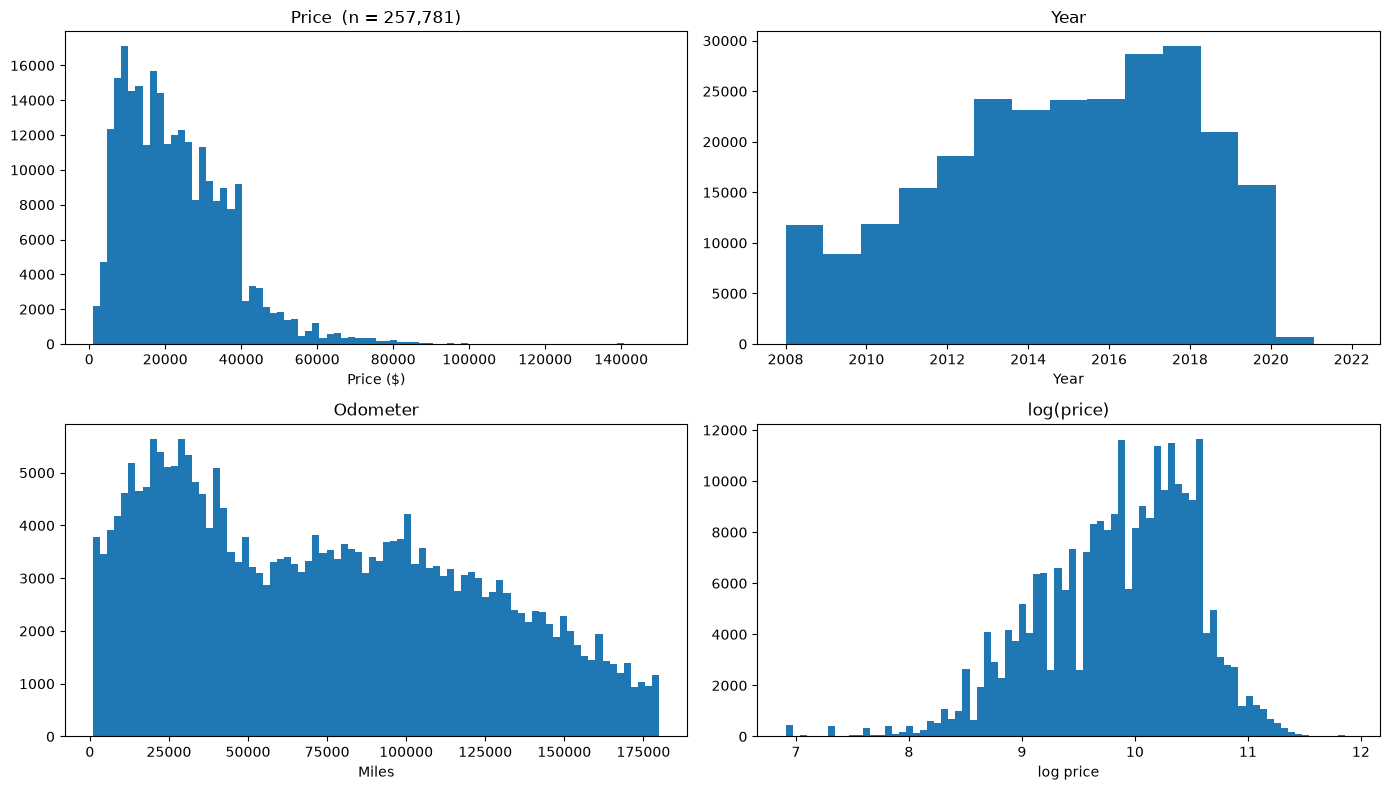

Filtered price summary:
count    257781.0
mean      23110.0
std       14268.0
min        1000.0
25%       11995.0
50%       20488.0
75%       31590.0
max      150000.0
Name: price, dtype: float64

Filtered year summary:
count    257781.0
mean       2015.0
std           3.0
min        2008.0
25%        2012.0
50%        2015.0
75%        2018.0
max        2022.0
Name: year, dtype: float64

Filtered odometer summary:
count    257781.0
mean      74056.0
std       47582.0
min        1000.0
25%       31246.0
50%       70159.0
75%      111195.0
max      180000.0
Name: odometer, dtype: float64


In [8]:
#Now we confirm each filtered variable behaves as intended.

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

axes[0, 0].hist(df_clean["price"], bins=80) #Histogram of price
axes[0, 0].set_title(f"Price  (n = {len(df_clean):,})")
axes[0, 0].set_xlabel("Price ($)")

axes[0, 1].hist(df_clean["year"], bins=15) #Histogram of year
axes[0, 1].set_title("Year")
axes[0, 1].set_xlabel("Year")

axes[1, 0].hist(df_clean["odometer"], bins=80) #Histogram of odometer
axes[1, 0].set_title("Odometer")
axes[1, 0].set_xlabel("Miles")

axes[1, 1].hist(np.log(df_clean["price"]), bins=80) #Histogram of log(price)
axes[1, 1].set_title("log(price)")
axes[1, 1].set_xlabel("log price")

plt.tight_layout()
plt.show()

print("Filtered price summary:")
print(df_clean["price"].describe().round(0))
print()
print("Filtered year summary:")
print(df_clean["year"].describe().round(0))
print()
print("Filtered odometer summary:")
print(df_clean["odometer"].describe().round(0))

In [9]:
#Now confirm categorical coverage is preserved. Some filters might unexpectedly drop one category.
#This will also just clean dtypes

cat_cols = ["manufacturer", "condition", "cylinders", "fuel",
            "transmission", "drive", "size", "type", "paint_color", "state"]

print("Non-null fraction by categorical predictor (post-filter):")
print(df_clean[cat_cols].notna().mean().round(3).sort_values())
print()

print("Top categories within key predictors:")
for c in ["manufacturer", "type", "fuel", "drive"]:
    print(f"\n--- {c} ---")
    print(df_clean[c].value_counts().head(8))
print()

print("Condition distribution (post-filter):")
print(df_clean["condition"].value_counts(dropna=False))

Non-null fraction by categorical predictor (post-filter):
size            0.237
cylinders       0.547
condition       0.602
drive           0.702
paint_color     0.741
type            0.827
manufacturer    0.978
fuel            0.995
transmission    0.996
state           1.000
dtype: float64

Top categories within key predictors:

--- manufacturer ---
manufacturer
ford         41660
chevrolet    31114
toyota       19361
nissan       12192
jeep         11724
honda        11645
ram          11452
bmw          10729
Name: count, dtype: int64

--- type ---
type
sedan        57035
SUV          48087
pickup       30480
truck        17907
other        16821
hatchback    12930
coupe        11718
wagon         7355
Name: count, dtype: int64

--- fuel ---
fuel
gas         211808
other        25361
diesel       14055
hybrid        3826
electric      1440
Name: count, dtype: int64

--- drive ---
drive
4wd    80302
fwd    69788
rwd    30851
Name: count, dtype: int64

Condition distribution (post-fi

### Filtering results

The sequential filters reduced the raw dataset from 426,880 to 257,781 rows - 60.4% of the original. The retention rate is higher than expected due to the substantial signal overlap. 

Two observations stand out in the step-by-step drops:

First, the year filter (2008 - 2022) is the single largest contributor, removing about 20% of the dataset. This is not a distress signal in the same sense as a salvage title. Its a scope decision: older vehicles have different depreciation dynamics, and their presence would complicate the modeling without adding much inference. 

Second, the condition filter drops only 555 rows. This is expected as `fair` and `salvage` categories together make up less than 2% of listings, and most of them were likely already removed by the earlier title and price filters. 

### Categorical coverage

Coverage of the categorical predictors varies widely after filtering. 

**Well-covered predictors (95%+).** `manufacturer`, `fuel`, `transmission`,
and `state` are essentially complete. These will carry the full weight of
the categorical signal in the model.

**Moderately-covered predictors (70–85%).** `type`, `paint_color`, and
`drive` retain enough coverage to be useful. Missing values will be treated
as an explicit `"Unknown"` level so the model can estimate whether
missingness itself is informative.

**Sparsely-covered predictors (25–60%).** `condition`, `cylinders`, and
especially `size` are poorly populated. `size` at 23.7% coverage is the
weakest. Including it with an `"Unknown"` level is still possible, but its
coefficient will be driven by a minority of the data. It may be worth
dropping entirely in the modeling notebook, or retaining only as a
binary "is size declared" flag.

### What this means for the modeling stage
There are three pratical adjustments to consider: 

1. **High-cardinality categoricals.** `manufacturer` has 42 levels, `model` has thousands. `model` will likely need to be dropped or target-encoded. `manufacturer` can be one-hot encoded directly. 
2. **Sparse categories.** `size` and `electric` fuel (1,440 listings) will need to be consolidated or dropped. 
3. **Missing categorical values.** All categorical predictors except `state` have some missingness. The cleanest approach may be to fill with `"Unknown"` before encoding, so missingness becomes a level rather than a dropped row. 

## Section 3 - Listing Metadata

The `description` field was investigated as a source of additional predictors and is deliberately not used. However, we may construct one feature in this section, and it comes fromm a structural field rather than from prose: `is_dealer`, derived from the Craigslist URL path. 

The modeling stage will work with structured predictors and this single listing-metadata feature.

In [10]:
# is_dealer is derived from the Craigslist URL path:
#   /ctd/ = "cars and trucks by dealer"
#   /cto/ = "cars and trucks by owner" (private party)

df_clean["is_dealer"] = df_clean["url"].str.contains("/ctd/", na=False).astype(int)

dealer_n = df_clean["is_dealer"].sum()
private_n = len(df_clean) - dealer_n

print(f"Dealer listings:  {dealer_n:>7,}  ({100 * dealer_n / len(df_clean):.1f}%)")
print(f"Private listings: {private_n:>7,}  ({100 * private_n / len(df_clean):.1f}%)")

Dealer listings:  231,169  (89.7%)
Private listings:  26,612  (10.3%)


### What this means for the project

The filtered subset is 89.7% dealer listings and 10.3% private listings. This may be a direct consequence of the Section 2 filters. Private-party Craigslist inventory is concentrated in older, higher-mileage, cheaper, and non-clean-title vehicles. 

Therefore, this model is effectively a dealer-inventory pricing model, with a private-party subsample large enough to estimate a comparison coefficient.

In [11]:
# Are the private-party listings that survived the filters representative, or are they a specific subset?

private = df_clean[df_clean["is_dealer"] == 0]
dealer = df_clean[df_clean["is_dealer"] == 1]

print("Private-party inventory (n = {:,}):".format(len(private)))
print(private[["price", "year", "odometer"]].describe().round(0))
print()
print("Dealer inventory (n = {:,}):".format(len(dealer)))
print(dealer[["price", "year", "odometer"]].describe().round(0))

Private-party inventory (n = 26,612):
          price     year  odometer
count   26612.0  26612.0   26612.0
mean    15329.0   2013.0   99082.0
std     13735.0      3.0   45370.0
min      1000.0   2008.0    1000.0
25%      6800.0   2010.0   65132.0
50%     10500.0   2012.0  102000.0
75%     18700.0   2015.0  135000.0
max    150000.0   2022.0  180000.0

Dealer inventory (n = 231,169):
          price      year  odometer
count  231169.0  231169.0  231169.0
mean    24006.0    2015.0   71174.0
std     14055.0       3.0   46982.0
min      1000.0    2008.0    1000.0
25%     13250.0    2013.0   29530.0
50%     21990.0    2015.0   65494.0
75%     32000.0    2018.0  107422.0
max    149998.0    2022.0  180000.0


In [12]:
#Just a sanity check on the raw dataframe
raw_dealer = df["url"].str.contains("/ctd/", na=False).sum()
raw_private = df["url"].str.contains("/cto/", na=False).sum()
raw_other = len(df) - raw_dealer - raw_private

print(f"Raw /ctd/:  {raw_dealer:>7,}  ({100 * raw_dealer / len(df):.1f}%)")
print(f"Raw /cto/:  {raw_private:>7,}  ({100 * raw_private / len(df):.1f}%)")
print(f"Neither:    {raw_other:>7,}  ({100 * raw_other / len(df):.1f}%)")

Raw /ctd/:  341,989  (80.1%)
Raw /cto/:   84,891  (19.9%)
Neither:          0  (0.0%)


Before filtering, the raw dataset was 80.1% dealer and 19.8% private. After filtering, it's 89.7% dealer and 10.3% private. That means the filters cut dealer inventory by ~32% and private-party inventory by ~69%. This is a pattern that was expected. 

## Section 4 - Derived Predictors and Target

Two categories of derived features are constructed here: 

1. **Geographic.** `census_region` (4 levels) and `dist_to_major_metro` (numeric, miles) are derived from `state` and `lat`/`long`. These capture regional and urban/rural price variation that the raw coordinates cannot.

2. **Target transformation.** `log_price = log(price)`. Price is right-skewed; the log transform stabilizes variance. 

In [13]:
df_clean["log_price"] = np.log(df_clean["price"])

print("log_price summary:")
print(df_clean["log_price"].describe().round(3))

log_price summary:
count    257781.000
mean          9.844
std           0.683
min           6.908
25%           9.392
50%           9.928
75%          10.361
max          11.918
Name: log_price, dtype: float64


In [15]:
# Map each state to a US Census region.
# Source: US Census Bureau standard four-region classification.

REGION_MAP = {
    # Northeast
    "ct": "Northeast", "me": "Northeast", "ma": "Northeast", "nh": "Northeast",
    "ri": "Northeast", "vt": "Northeast", "nj": "Northeast", "ny": "Northeast",
    "pa": "Northeast",
    # Midwest
    "il": "Midwest", "in": "Midwest", "mi": "Midwest", "oh": "Midwest",
    "wi": "Midwest", "ia": "Midwest", "ks": "Midwest", "mn": "Midwest",
    "mo": "Midwest", "ne": "Midwest", "nd": "Midwest", "sd": "Midwest",
    # South
    "de": "South", "fl": "South", "ga": "South", "md": "South", "nc": "South",
    "sc": "South", "va": "South", "dc": "South", "wv": "South", "al": "South",
    "ky": "South", "ms": "South", "tn": "South", "ar": "South", "la": "South",
    "ok": "South", "tx": "South",
    # West
    "az": "West", "co": "West", "id": "West", "mt": "West", "nv": "West",
    "nm": "West", "ut": "West", "wy": "West", "ak": "West", "ca": "West",
    "hi": "West", "or": "West", "wa": "West",
}

df_clean["census_region"] = df_clean["state"].map(REGION_MAP)

print("census_region distribution:")
print(df_clean["census_region"].value_counts(dropna=False))

census_region distribution:
census_region
South        83195
West         75808
Midwest      55786
Northeast    42992
Name: count, dtype: int64


In [16]:
# Distance from each listing to the nearest of the top-20 US metro areas.
# Coordinates are approximate metro centroids.

MAJOR_METROS = {
    "new_york":      (40.7128,  -74.0060),
    "los_angeles":   (34.0522, -118.2437),
    "chicago":       (41.8781,  -87.6298),
    "dallas":        (32.7767,  -96.7970),
    "houston":       (29.7604,  -95.3698),
    "washington_dc": (38.9072,  -77.0369),
    "miami":         (25.7617,  -80.1918),
    "philadelphia":  (39.9526,  -75.1652),
    "atlanta":       (33.7490,  -84.3880),
    "phoenix":       (33.4484, -112.0740),
    "boston":        (42.3601,  -71.0589),
    "san_francisco": (37.7749, -122.4194),
    "riverside":     (33.9533, -117.3962),
    "detroit":       (42.3314,  -83.0458),
    "seattle":       (47.6062, -122.3321),
    "minneapolis":   (44.9778,  -93.2650),
    "san_diego":     (32.7157, -117.1611),
    "tampa":         (27.9506,  -82.4572),
    "denver":        (39.7392, -104.9903),
    "st_louis":      (38.6270,  -90.1994),
}

def haversine_miles(lat1, lon1, lat2, lon2): # Calculate the great-circle distance in miles between two latitude/longitude points.
    """Great-circle distance in miles between two lat/lon points."""
    R = 3958.8  # Earth radius in miles
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
    return 2 * R * np.arcsin(np.sqrt(a))

def min_metro_distance(lat, lon): # Calculate the distance to the nearest major metro in miles.
    if pd.isna(lat) or pd.isna(lon):
        return np.nan
    return min(haversine_miles(lat, lon, m_lat, m_lon)
               for m_lat, m_lon in MAJOR_METROS.values())

df_clean["dist_to_major_metro"] = [
    min_metro_distance(lat, lon)
    for lat, lon in zip(df_clean["lat"], df_clean["long"])
]

print("dist_to_major_metro summary (miles):")
print(df_clean["dist_to_major_metro"].describe().round(1))
print(f"\nMissing: {df_clean['dist_to_major_metro'].isna().sum():,} "
      f"({100 * df_clean['dist_to_major_metro'].isna().mean():.2f}%)")

dist_to_major_metro summary (miles):
count    254950.0
mean        158.9
std         253.6
min           0.0
25%          41.4
50%         111.9
75%         195.1
max        7375.0
Name: dist_to_major_metro, dtype: float64

Missing: 2,831 (1.10%)


In [17]:
#Investigate the extreme distances
top_dist = df_clean.nlargest(20, "dist_to_major_metro")[
    ["state", "region", "lat", "long", "dist_to_major_metro"]
]
print(top_dist)

       state                region        lat        long  dist_to_major_metro
415144    wi  appleton-oshkosh-FDL -72.601807 -142.310028          7375.047868
217712    mn              st cloud  45.557900   94.163200          5631.331960
217718    mn              st cloud  45.557900   94.163200          5631.331960
217720    mn              st cloud  45.557900   94.163200          5631.331960
174152    ky             owensboro -10.848244   -6.416016          5485.942375
269111    ny          finger lakes -38.115380 -129.023760          4953.110322
257026    nj          south jersey  40.564085  129.287109          4934.178381
424164    wi             milwaukee   7.021805   -7.021101          4574.538985
38139     ca               modesto -37.029731 -102.339284          4571.272543
39305     ca               modesto -37.029731 -102.339284          4571.272543
423598    wi             milwaukee   8.332999   -8.332801          4447.037684
189090    ma           south coast -23.023822 -101.1

In [18]:
# Validate coordinates, clear error for some. 
valid_coords = (
    df_clean["lat"].between(18, 72) & #Should spand the continental US
    df_clean["long"].between(-180, -65)
)

bad_coords = ~valid_coords
print(f"Listings with implausible coordinates: {bad_coords.sum():,} "
      f"({100 * bad_coords.mean():.3f}%)")

# Null out the distance for those rows rather than dropping them
df_clean.loc[bad_coords, "dist_to_major_metro"] = np.nan

Listings with implausible coordinates: 2,857 (1.108%)


In [19]:
#Finally, dropping unnecessary columns from the cleaned dataframe.
DROP_COLS = [
    "id", "url", "region_url", "image_url", "VIN",
    "county", "posting_date",
    "title_status",   # constant after Filter 1
    "region",         # 404 levels, redundant with state
    "description",    # deliberately unused
    "lat", "long",    # superseded by derived features
]

df_clean = df_clean.drop(columns=[c for c in DROP_COLS if c in df_clean.columns])

print(f"Final shape: {df_clean.shape}")
print("\nColumns:")
for c in sorted(df_clean.columns):
    print(f"  {c}")

Final shape: (257781, 18)

Columns:
  census_region
  condition
  cylinders
  dist_to_major_metro
  drive
  fuel
  is_dealer
  log_price
  manufacturer
  model
  odometer
  paint_color
  price
  size
  state
  transmission
  type
  year


### Section 4 Findings

**Target transformation.** `log_price` has a mean 9.84 (=$18,830) and looks approximately normal. 

**Census Region.** The distribution looks proportional to the US population and car-market density. No region is really underrepresented. 

**Distance to major metro.** Initial summary showed a maximum of 7,375 miles, which is not physically possible for any US location. Investigation of the 20 largest distances revealed three groups: 

1. **Legitimate Hawaii listings** (3 rows, ~2,450–2,465 miles). Hawaii is genuinely that far from the nearest mainland metro.
2. **Sign-flipped coordinates** (e.g., a Minnesota listing with longitude +94.16 instead of −94.16).
3. **Nonsense coordinate pairs** (e.g., a Kentucky listing at latitud −10.85, longitude −6.42). These are not recoverable.

We filtered to plausible US bounds (18 ≤ lat ≤ 72, −180 ≤ long ≤ −65) and set `dist_to_major_metro` to NaN for listings outside those bounds.


## Section 5 - Final Sanity Checks and Save

Before saving, we verify the cleaned subset is internally consistent. The goal is to catch silent failures - filters that removed more than intended, features that are constant, or a drifted target. 

In [22]:
# Target
print("log_price summary:")
print(df_clean["log_price"].describe().round(3))
print()

# Numeric predictors
print("odometer summary:")
print(df_clean["odometer"].describe().round(0))
print()
print("dist_to_major_metro summary:")
print(df_clean["dist_to_major_metro"].describe().round(1))
print()

# Categorical coverage
cat_cols = ["manufacturer", "condition", "cylinders", "fuel",
            "transmission", "drive", "size", "type", "paint_color",
            "state", "census_region"]
print("Non-null fraction by categorical predictor:")
print(df_clean[cat_cols].notna().mean().round(3).sort_values())
print()

# Constant columns
nunique = df_clean.nunique()
constant_cols = nunique[nunique <= 1].index.tolist()
if constant_cols:
    print(f"WARNING — constant columns: {constant_cols}")
else:
    print("No constant columns.")

# Final row count
print(f"\nFinal rows: {len(df_clean):,}")

log_price summary:
count    257781.000
mean          9.844
std           0.683
min           6.908
25%           9.392
50%           9.928
75%          10.361
max          11.918
Name: log_price, dtype: float64

odometer summary:
count    257781.0
mean      74056.0
std       47582.0
min        1000.0
25%       31246.0
50%       70159.0
75%      111195.0
max      180000.0
Name: odometer, dtype: float64

dist_to_major_metro summary:
count    254924.0
mean        158.5
std         250.8
min           0.0
25%          41.4
50%         111.9
75%         195.1
max        2465.3
Name: dist_to_major_metro, dtype: float64

Non-null fraction by categorical predictor:
size             0.237
cylinders        0.547
condition        0.602
drive            0.702
paint_color      0.741
type             0.827
manufacturer     0.978
fuel             0.995
transmission     0.996
state            1.000
census_region    1.000
dtype: float64

No constant columns.

Final rows: 257,781


In [25]:
#High-cardinality categoricals that will need handling in the modeling stage.

print("Cardinality of categorical predictors:")
for c in ["manufacturer", "model", "type", "paint_color", "state",
          "census_region"]:
    if c in df_clean.columns:
        print(f"  {c:18s}  {df_clean[c].nunique():>6,} unique")

Cardinality of categorical predictors:
  manufacturer            40 unique
  model               15,141 unique
  type                    13 unique
  paint_color             12 unique
  state                   51 unique
  census_region            4 unique


In [24]:
out_path = OUT_DIR / "modeling_subset.csv"
df_clean.to_csv(out_path, index=False)
print(f"Saved {len(df_clean):,} rows × {df_clean.shape[1]} columns to {out_path}")

Saved 257,781 rows × 18 columns to C:\Users\alecp\MyPrograms\STA 334\used_vehicle_prediction\vehicle_data\processed\modeling_subset.csv


### Section 5 Conclusion

The cleaned subset contains 257,781 rows and 18 columns. Sanity checks confirm: 
- The target (`log_price`) is well-behaved. 
- All categorical predictors except `size` retain at least 50% converage. 
- No numeric predictor has impossible values
- `title_status` was constant and therefore dropped for modeling. 

The subset is ready for the modeling stage, subject to two preparatory steps in `03_modeling.ipynb`: 

1. **Handle high cardinality.** `model` may have to be dropped. `manufacturer` (40 levels) and `state` (51 levels) will have to be one-hot encoded. 
2. **Impute or encode missing mategorical values** Missing values in `condition`, `cylinders`, `drive`, `paint_color`, `size`, and `type` will be filled with an `"Unknown"` level so the model can estimate whether missingness is informative. 

This concludes our `02_features.ipynb` notebook. 
